# `Pandas`: dataframe manipulation, extraction, sorting, and an introduction to plotting with `matplotlib`

- continuing with `pandas` from week 12
- manipulating dataframes
- subsetting, summarizing, sorting, and building dataframes
- introduction to basic plotting with `matplotlib`

## Reading files straight into dataframe and examining dataframe object.

`pandas` is built to read, write, and manipulate dataframes, or mutliple dataframes. A dataframe is a two-dimensional tabular data structure with labeled axes (rows and columns). A `pandas` data frame consists of three elements: the data, rows, and columns. 

Step one is reading a file directly into a dataframe, which is simple as illustrated below. `.head()` can be used to preview the top five lines of the file, and `pandas` automatically treats column and row headers as read or inferred. The file we are reading in below contains a list of *Pinus muricata* populations across different regions along the coast of California, the only places on Earth where this species grows.

In [9]:
import pandas as pd

muricata_df = pd.read_csv('muricata_pops_lat_long.csv')
muricata_df.head()


,region,pop,lat,long
0,SCI,CH,34.003334,-119.614283
1,SCI,LO,34.003334,-119.614283
2,SCI,CP,34.013676,-119.797136
3,SOC,RR,34.013676,-119.797136
4,SLO,PB,34.024463,-119.692431


### Simple useful functions for describing dataframe:

There are many many built in functions for summarizing, manipulating, merging, and converting `pandas` dataframes. As with other data structures in python, these are called with the format dataframe_name_df.function_name. In jupyter notebooks, IDEs, or interactive python terminals, you can access a list of available functions by hitting tab after `dataframe_name_df.`.

In [10]:
dfshape = muricata_df.shape
dfsize = muricata_df.size
dfcols= muricata_df.columns
print("data frame shape: ", dfshape, "; dataframe size: , ", dfsize, "; dataframe column names: ", dfcols)

data frame shape:  (14, 4) ; dataframe size: ,  56 ; dataframe column names:  Index(['region', 'pop', 'lat', 'long'], dtype='object')


A column can be chosen as the index column, which allows for quick extraction or manipulation based on an indexing variable. Below we set the region column to index, and the output using `.loc` represents the data for all rows representing the regions "SCI".

In [11]:
muricata_df = pd.read_csv("muricata_pops_lat_long.csv", index_col ="region")
muricata_df.loc['SCI']


,pop,lat,long
region,,,
SCI,CH,34.003334,-119.614283
SCI,LO,34.003334,-119.614283
SCI,CP,34.013676,-119.797136


## Manipulating dataframes

Among the strengths of `pandas`, there are many built in dataframe functions to reshape, extract from, add to, or do math on dataframe values.

For the example code below, we will read in the `states_covid.csv` file that resides (or should) in the same directory as this jupyter notebook for python8. 

### Covid data for the demo contained below

Data downloaded from: https://github.com/COVID19Tracking/covid-tracking-data   
(data stopped updating March, 2021) 

In [14]:
state_covid_df = pd.read_csv('states_covid.csv', index_col ="state") #read in csv, set state as index
state_covid_df.head() #views the top 5 lines
#state_covid_df.shape

,date,death,deathConfirmed,deathIncrease,deathProbable,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,inIcuCumulative,...,totalTestResults,totalTestResultsIncrease,totalTestsAntibody,totalTestsAntigen,totalTestsPeopleAntibody,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
state,,,,,,,,,,,,,,,,,,,,,
AK,2021-02-23,290.0,NaN,0,NaN,1260.0,1260.0,38.0,9,NaN,...,1653425.0,4640,NaN,NaN,NaN,NaN,NaN,0,1653425.0,4640
AL,2021-02-23,9660.0,7575.0,68,2085.0,45250.0,45250.0,762.0,122,2632.0,...,2265086.0,4825,NaN,NaN,115256.0,NaN,2265086.0,4825,NaN,0
AR,2021-02-23,5377.0,4321.0,14,1056.0,14617.0,14617.0,545.0,47,NaN,...,2609837.0,4779,NaN,NaN,NaN,436309.0,NaN,0,2609837.0,4779
AS,2021-02-23,0.0,NaN,0,NaN,NaN,NaN,NaN,0,NaN,...,2140.0,0,NaN,NaN,NaN,NaN,NaN,0,2140.0,0
AZ,2021-02-23,15650.0,13821.0,148,1829.0,57072.0,57072.0,1515.0,78,NaN,...,7478323.0,19439,435091.0,NaN,NaN,NaN,3709365.0,6212,7478323.0,19439


#### The `.info()` function will display the information on each variable type.
This is a useful quality control step to see how variables are being treated on default after creating a dataframe.

In [15]:
state_covid_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20108 entries, AK to WA
Data columns (total 40 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   date                              20108 non-null  object 
 1   death                             19230 non-null  float64
 2   deathConfirmed                    9407 non-null   float64
 3   deathIncrease                     20108 non-null  int64  
 4   deathProbable                     7249 non-null   float64
 5   hospitalized                      12435 non-null  float64
 6   hospitalizedCumulative            12435 non-null  float64
 7   hospitalizedCurrently             16702 non-null  float64
 8   hospitalizedIncrease              20108 non-null  int64  
 9   inIcuCumulative                   3648 non-null   float64
 10  inIcuCurrently                    11030 non-null  float64
 11  negative                          15640 non-null  float64
 12  negativeInc

#### Because we used `index_col = 'state'`, we can pull data just for one state simply by:

In [16]:
state_covid_df.loc['NV']

,date,death,deathConfirmed,deathIncrease,deathProbable,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,inIcuCumulative,...,totalTestResults,totalTestResultsIncrease,totalTestsAntibody,totalTestsAntigen,totalTestsPeopleAntibody,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
state,,,,,,,,,,,,,,,,,,,,,
NV,2021-02-23,4903.0,NaN,21,NaN,NaN,NaN,581.0,0,NaN,...,2678249.0,10449,NaN,NaN,NaN,NaN,1398191.0,3837,NaN,0
NV,2021-02-22,4882.0,NaN,10,NaN,NaN,NaN,580.0,0,NaN,...,2667800.0,4933,NaN,NaN,NaN,NaN,1394354.0,1436,NaN,0
NV,2021-02-21,4872.0,NaN,4,NaN,NaN,NaN,639.0,0,NaN,...,2662867.0,6034,NaN,NaN,NaN,NaN,1392918.0,2108,NaN,0
NV,2021-02-20,4868.0,NaN,37,NaN,NaN,NaN,639.0,0,NaN,...,2656833.0,6747,NaN,NaN,NaN,NaN,1390810.0,1905,NaN,0
NV,2021-02-19,4831.0,NaN,26,NaN,NaN,NaN,670.0,0,NaN,...,2650086.0,7193,NaN,NaN,NaN,NaN,1388905.0,2127,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NV,2020-03-09,0.0,NaN,0,NaN,NaN,NaN,NaN,0,NaN,...,126.0,23,NaN,NaN,NaN,NaN,NaN,0,NaN,0
NV,2020-03-08,0.0,NaN,0,NaN,NaN,NaN,NaN,0,NaN,...,103.0,30,NaN,NaN,NaN,NaN,NaN,0,NaN,0
NV,2020-03-07,0.0,NaN,0,NaN,NaN,NaN,NaN,0,NaN,...,73.0,25,NaN,NaN,NaN,NaN,NaN,0,NaN,0


#### We can pull data by specifying column names easily:

We can do this one column at a time

In [10]:
state_covid_df['death']

state
AK      290.0
AL     9660.0
AR     5377.0
AS        0.0
AZ    15650.0
       ...   
WA        NaN
WA        NaN
WA        NaN
WA        NaN
WA        NaN
Name: death, Length: 20108, dtype: float64

#### OR multiple columns at a time:

In [17]:
state_covid_df[['death', 'deathIncrease', 'hospitalizedCurrently']]

,death,deathIncrease,hospitalizedCurrently
state,,,
AK,290.0,0,38.0
AL,9660.0,68,762.0
AR,5377.0,14,545.0
AS,0.0,0,NaN
AZ,15650.0,148,1515.0
...,...,...,...
WA,NaN,0,NaN
WA,NaN,0,NaN
WA,NaN,0,NaN


#### Lists of columns can be specified, useful for creating a new dataframe with a subset of information.

Below a new dataframe is made from a subset of the columns from `state_covid_df`. Note that double brackets are used when a list is provided.

In [18]:
state_covid_df = pd.read_csv('states_covid.csv')
new_covid_df = state_covid_df[['date','state','death','positive','negative','totalTestResults']]
new_covid_df.head() 

,date,state,death,positive,negative,totalTestResults
0,2021-02-23,AK,290.0,55560.0,NaN,1653425.0
1,2021-02-23,AL,9660.0,488973.0,1882180.0,2265086.0
2,2021-02-23,AR,5377.0,316593.0,2359571.0,2609837.0
3,2021-02-23,AS,0.0,0.0,2140.0,2140.0
4,2021-02-23,AZ,15650.0,810658.0,2953210.0,7478323.0


#### Columns can be renamed using `.columns` or `.rename` 

To change the name of all columns, a new list of column names can be provided (although a name must be provided for each and all columns). Below we are just changing `totalTestResults` to `total`:

`new_covid_df.columns = ['date','state','death','positive','negative','total']`  

Code below illustrates one way to change just one column:
axis = (0 = rows, 1 = columns)  
inplace=True replaces the current DataFrame, same as (df = df.DOSOMETHING)

`new_covid_df.rename({'totalTestResults':'total'},axis=1,inplace=True)`

In [21]:
new_covid_df.columns = ['date','state','death','positive','negative','total']  # same as example above for changing column name
new_covid_df.head()

,date,state,death,positive,negative,total
0,2021-02-23,AK,290.0,55560.0,NaN,1653425.0
1,2021-02-23,AL,9660.0,488973.0,1882180.0,2265086.0
2,2021-02-23,AR,5377.0,316593.0,2359571.0,2609837.0
3,2021-02-23,AS,0.0,0.0,2140.0,2140.0
4,2021-02-23,AZ,15650.0,810658.0,2953210.0,7478323.0


#### Columns can be reordered
Two ways to do this illustrated below:

`new_covid_df = new_covid_df[['date','state','total','negative','positive','death']]`  
`new_covid_df = new_covid_df.iloc[:,[0,1,5,4,3,2]]` #iloc is how you access df like a matrix

In [22]:
new_covid_df = new_covid_df[['date','state','total','negative','positive','death']]
new_covid_df.head()

,date,state,total,negative,positive,death
0,2021-02-23,AK,1653425.0,NaN,55560.0,290.0
1,2021-02-23,AL,2265086.0,1882180.0,488973.0,9660.0
2,2021-02-23,AR,2609837.0,2359571.0,316593.0,5377.0
3,2021-02-23,AS,2140.0,2140.0,0.0,0.0
4,2021-02-23,AZ,7478323.0,2953210.0,810658.0,15650.0


#### add a column (positivity rate)
`new_covid_df['rate'] = new_covid_df.positive / new_covid_df.total` #alternate way

In [23]:
new_covid_df['rate'] = new_covid_df['positive'] / new_covid_df['total']
new_covid_df.head()

/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_38915/88793205.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,date,state,total,negative,positive,death,rate
0,2021-02-23,AK,1653425.0,NaN,55560.0,290.0,0.033603
1,2021-02-23,AL,2265086.0,1882180.0,488973.0,9660.0,0.215874
2,2021-02-23,AR,2609837.0,2359571.0,316593.0,5377.0,0.121308
3,2021-02-23,AS,2140.0,2140.0,0.0,0.0,0.000000
4,2021-02-23,AZ,7478323.0,2953210.0,810658.0,15650.0,0.108401


#### Date manipulation
`pandas` allows manipulation or conversion of dates to more consistent formats. Below is one example of how to convert dates to different formats, and to see how dates are treated (see `new_covid_df.info()` below). For more information on `pd.to_datetime()` see [pandas documentation for datetime](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html)

In [24]:
new_covid_df["date"]= pd.to_datetime(new_covid_df["date"],yearfirst=True) 
new_covid_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20108 entries, 0 to 20107
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      20108 non-null  datetime64[ns]
 1   state     20108 non-null  object        
 2   total     20006 non-null  float64       
 3   negative  15640 non-null  float64       
 4   positive  19912 non-null  float64       
 5   death     19230 non-null  float64       
 6   rate      19824 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 1.1+ MB


/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_38915/710168377.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



#### Below we add a new column for day of year, which is created based on the year first dates listed in the first column.

In [25]:
new_covid_df['dayofyear'] = new_covid_df['date'].dt.dayofyear
new_covid_df.head()

/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_38915/3145453802.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,date,state,total,negative,positive,death,rate,dayofyear
0,2021-02-23,AK,1653425.0,NaN,55560.0,290.0,0.033603,54
1,2021-02-23,AL,2265086.0,1882180.0,488973.0,9660.0,0.215874,54
2,2021-02-23,AR,2609837.0,2359571.0,316593.0,5377.0,0.121308,54
3,2021-02-23,AS,2140.0,2140.0,0.0,0.0,0.000000,54
4,2021-02-23,AZ,7478323.0,2953210.0,810658.0,15650.0,0.108401,54


####  `pandas` makes subsetting/filtering data flexible and fast

Below we will subset or filter on multiple columns and data types (numeric or string)

First, we'll subset on Nevada only and then have a look at what this is doing.

In [26]:
new_covid_df.state == 'NV'


0        False
1        False
2        False
3        False
4        False
         ...  
20103    False
20104    False
20105    False
20106    False
20107    False
Name: state, Length: 20108, dtype: bool

You can't really see where but it is outputtig a list of boolean (True,False) in the order they are found. If you put this statement as an index, it will keep only the Trues

#### Below we create a new dataframe that just contains data for state == NV

In [27]:
NV_covid_df = new_covid_df[new_covid_df.state == 'NV']
NV_covid_df.head()
#NV_covid_df.shape

,date,state,total,negative,positive,death,rate,dayofyear
36,2021-02-23,NV,2678249.0,1106648.0,291543.0,4903.0,0.108856,54
92,2021-02-22,NV,2667800.0,1103209.0,291145.0,4882.0,0.109133,53
148,2021-02-21,NV,2662867.0,1101946.0,290972.0,4872.0,0.109270,52
204,2021-02-20,NV,2656833.0,1100139.0,290671.0,4868.0,0.109405,51
260,2021-02-19,NV,2650086.0,1098605.0,290300.0,4831.0,0.109544,50


#### Filtering or data subsetting can easily be controlled 

Let's filter on state and something numeric

| means or   
& means and

In [28]:
new_covid_df[(new_covid_df.state == 'NV') & (new_covid_df.rate > 0.10)]

,date,state,total,negative,positive,death,rate,dayofyear
36,2021-02-23,NV,2678249.0,1106648.0,291543.0,4903.0,0.108856,54
92,2021-02-22,NV,2667800.0,1103209.0,291145.0,4882.0,0.109133,53
148,2021-02-21,NV,2662867.0,1101946.0,290972.0,4872.0,0.109270,52
204,2021-02-20,NV,2656833.0,1100139.0,290671.0,4868.0,0.109405,51
260,2021-02-19,NV,2650086.0,1098605.0,290300.0,4831.0,0.109544,50
...,...,...,...,...,...,...,...,...
17508,2020-04-17,NV,33881.0,26238.0,3524.0,162.0,0.104011,108
17564,2020-04-16,NV,32746.0,25130.0,3321.0,158.0,0.101417,107
17620,2020-04-15,NV,31276.0,24444.0,3211.0,150.0,0.102667,106
17676,2020-04-14,NV,30241.0,23573.0,3088.0,141.0,0.102113,105


`df.query()` is another way that might look a little cleaner for more complicated filtering  
be careful with syntax of quotations 

In [29]:
new_covid_df.query("state == 'NV' & rate > 0.10 & death > 4500")

,date,state,total,negative,positive,death,rate,dayofyear
36,2021-02-23,NV,2678249.0,1106648.0,291543.0,4903.0,0.108856,54
92,2021-02-22,NV,2667800.0,1103209.0,291145.0,4882.0,0.109133,53
148,2021-02-21,NV,2662867.0,1101946.0,290972.0,4872.0,0.109270,52
204,2021-02-20,NV,2656833.0,1100139.0,290671.0,4868.0,0.109405,51
260,2021-02-19,NV,2650086.0,1098605.0,290300.0,4831.0,0.109544,50
316,2021-02-18,NV,2642893.0,1096898.0,289880.0,4805.0,0.109683,49
372,2021-02-17,NV,2634991.0,1094532.0,289392.0,4774.0,0.109827,48
428,2021-02-16,NV,2626777.0,1090831.0,289029.0,4733.0,0.110032,47
484,2021-02-15,NV,2618806.0,1087551.0,288739.0,4720.0,0.110256,46
540,2021-02-14,NV,2612420.0,1085885.0,288348.0,4709.0,0.110376,45


### Sorting dataframes
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.sort_values.html

The `.sort_values()` function enables sorting based on specific variables, and has considerable flexibility. 

Below we will sort based on the 'positive' column and look at the top 5 days using `.head`

In [30]:
new_covid_df.sort_values('positive',ascending=False,inplace=True)
new_covid_df.head()

/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_38915/507370238.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,date,state,total,negative,positive,death,rate,dayofyear
5,2021-02-23,CA,47513367.0,NaN,3450058.0,49563.0,0.072612,54
61,2021-02-22,CA,47320802.0,NaN,3446611.0,49338.0,0.072835,53
117,2021-02-21,CA,47043348.0,NaN,3441946.0,49105.0,0.073165,52
173,2021-02-20,CA,46813876.0,NaN,3435186.0,48825.0,0.073380,51
229,2021-02-19,CA,46621654.0,NaN,3428518.0,48344.0,0.073539,50


## Summarizing DataFrame

https://www.shanelynn.ie/summarising-aggregation-and-grouping-data-in-python-pandas/

Summarizing data is important for figures, statistics, and general reporting.

You will need **Bloom_etal_2018_Reduced_Dataset.csv** that is available in the same course github directory as this notebook. Make sure you are in the right directory and have the correct file.




In [31]:
bloom_df = pd.read_csv('Bloom_etal_2018_Reduced_Dataset.csv')
print(bloom_df.shape)
print(bloom_df.head())

(50, 4)
                   taxa  logbodysize  trophic_position         Reg
0        Alosa_alabamae     1.707570          0.431364  diadromous
1           Alosa_alosa     1.778151          0.556303  diadromous
2          Alosa_fallax     1.778151          0.556303  diadromous
3       Alosa_mediocris     1.778151          0.612784  diadromous
4  Alosa_pseudoharengus     1.602060          0.544068  diadromous


We can use `.unique()` to see how many categories there are in the Reg variable (column)

In [32]:
bloom_df['Reg'].unique()

array(['diadromous', 'non-diadromous'], dtype=object)

Now lets get some summary stats for *logbodysize* and *tropic_position* based on being diadromous or non-diadromous. Below we use the '.groupby' and `.agg` functions to group by the Reg variable and to generate means and counts of observations for each level of Reg.

In [25]:
print(bloom_df)

                           taxa  logbodysize  trophic_position             Reg
0                Alosa_alabamae     1.707570          0.431364      diadromous
1                   Alosa_alosa     1.778151          0.556303      diadromous
2                  Alosa_fallax     1.778151          0.556303      diadromous
3               Alosa_mediocris     1.778151          0.612784      diadromous
4          Alosa_pseudoharengus     1.602060          0.544068      diadromous
5             Alosa_sapidissima     1.790285          0.544068      diadromous
6      Amazonsprattus_scintilla     0.301030          0.531479  non-diadromous
7              Anchoa_chamensis     0.778151          0.518514  non-diadromous
8                 Anchoa_cubana     0.845098          0.518514  non-diadromous
9          Anchoa_delicatissima     0.903090          0.518514  non-diadromous
10          Anchoa_lamprotaenia     0.963788          0.531479  non-diadromous
11              Anchoa_lyolepis     0.845098        

In [27]:
bloom_reg_df = bloom_df.groupby('Reg')[['logbodysize','trophic_position']].agg(['mean', 'count'])


bloom_reg_df


logbodysize       trophic_position      
                      mean count             mean count
Reg                                                    
diadromous        1.507245    15         0.500777    15
non-diadromous    0.842018    35         0.500720    35

In [28]:
bloom_reg_df.index

Index(['diadromous', 'non-diadromous'], dtype='object', name='Reg')

**WARNING:** as you can see, this produced the desired result but the column names are now stacked and have what is known as a *MultiIndex* column name and needs to be flattened. You only need to worry about this if summarizing over more than one column

In [29]:
bloom_reg_df.columns

MultiIndex([(     'logbodysize',  'mean'),
            (     'logbodysize', 'count'),
            ('trophic_position',  'mean'),
            ('trophic_position', 'count')],
           )

Let's join the MultiIndex to a single column index like we are used to.

In [30]:
bloom_reg_df.columns = bloom_reg_df.columns.map('_'.join)
bloom_reg_df

,logbodysize_mean,logbodysize_count,trophic_position_mean,trophic_position_count
Reg,,,,
diadromous,1.507245,15,0.500777,15
non-diadromous,0.842018,35,0.500720,35


In [31]:
x = bloom_reg_df['logbodysize_count']
print(x)


Reg
diadromous        15
non-diadromous    35
Name: logbodysize_count, dtype: int64


Below we are grouping the covid data by 'states' using `.groupby`, then using `.agg` to calculate means, counts, variance, min and max for two of the variables.

In [33]:
state_covid_sub_df = pd.read_csv('states_covid.csv',parse_dates=['date'],infer_datetime_format=True,index_col='state')
result = state_covid_sub_df.groupby('state')[['death', 'deathConfirmed']].agg(['mean', 'count', 'var', 'min', 'max'])
result.head()

/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_38915/2114407394.py:1: FutureWarning:

The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.



death                                   deathConfirmed        \
              mean count           var  min      max           mean count   
state                                                                       
AK       78.628169   355  8.126511e+03  0.0    290.0      58.756098   246   
AL     2654.549133   346  5.906281e+06  0.0   9660.0    2706.175084   297   
AR     1586.351032   339  2.738435e+06  0.0   5377.0    2529.181818   165   
AS        0.000000   329  0.000000e+00  0.0      0.0            NaN     0   
AZ     4959.339080   348  1.737497e+07  0.0  15650.0    5972.616279   258   

                                      
                var     min      max  
state                                 
AK     3.152830e+03     9.0    215.0  
AL     3.431403e+06   290.0   7575.0  
AR     1.093576e+06   964.0   4321.0  
AS              NaN     NaN      NaN  
AZ     1.067279e+07  1060.0  13821.0

# Summary table of most common `pandas` functions


| **Category** | **Function / Method** | **Example Syntax** | **Purpose / Description** |
|---------------|------------------------|---------------------|----------------------------|
| **Importing & Exporting Data** | `pd.read_csv()` | `df = pd.read_csv("data.csv")` | Load CSV file into a DataFrame |
|  | `pd.read_excel()` | `df = pd.read_excel("file.xlsx", sheet_name="Sheet1")` | Read Excel spreadsheets |
|  | `pd.read_table()` | `df = pd.read_table("data.txt", sep="\t")` | Read tab-delimited text files |
|  | `pd.to_csv()` | `df.to_csv("output.csv", index=False)` | Write DataFrame to CSV file |
|  | `pd.to_excel()` | `df.to_excel("output.xlsx", index=False)` | Write DataFrame to Excel file |
| **Inspecting Data** | `df.head()` | `df.head(5)` | View first few rows |
|  | `df.tail()` | `df.tail(3)` | View last few rows |
|  | `df.info()` | `df.info()` | Summary of column names, data types, and memory usage |
|  | `df.describe()` | `df.describe()` | Summary statistics for numeric columns |
|  | `df.shape` | `df.shape` | Get number of rows and columns |
|  | `df.columns` | `df.columns` | Return column names |
|  | `df.dtypes` | `df.dtypes` | Show data type of each column |
| **Selecting & Filtering Data** | `df["col"]` | `df["Temperature"]` | Select a single column |
|  | `df[["col1", "col2"]]` | `df[["A", "B"]]` | Select multiple columns |
|  | `df.loc[]` | `df.loc[0:5, ["A","B"]]` | Select by label (rows and columns) |
|  | `df.iloc[]` | `df.iloc[0:5, 0:2]` | Select by integer position |
|  | `df.query()` | `df.query("tempF > 50")` | Filter rows using a string condition |
|  | `df[df["tempF"] > 50]` | — | Filter rows using a boolean condition |
| **Handling Missing Data** | `df.isna()` | `df.isna().sum()` | Detect missing (NaN) values |
|  | `df.dropna()` | `df.dropna(how="any")` | Remove missing rows |
|  | `df.fillna()` | `df.fillna(0)` | Replace NaNs with specified value |
|  | `df.interpolate()` | `df.interpolate()` | Fill missing values using interpolation |
| **Summarizing Data** | `df.mean()` | `df["tempF"].mean()` | Compute mean |
|  | `df.median()` | `df["tempF"].median()` | Compute median |
|  | `df.std()` | `df["tempF"].std()` | Compute standard deviation |
|  | `df.min()` / `df.max()` | `df["tempF"].max()` | Get minimum or maximum values |
|  | `df.value_counts()` | `df["Logger"].value_counts()` | Count unique occurrences |
|  | `df.groupby()` | `df.groupby("Logger")["tempF"].mean()` | Aggregate data by group |
| **Sorting & Rearranging** | `df.sort_values()` | `df.sort_values("tempF", ascending=False)` | Sort rows by a column |
|  | `df.sort_index()` | `df.sort_index()` | Sort by index |
|  | `df.reset_index()` | `df.reset_index(drop=True)` | Reset index to default |
|  | `df.set_index()` | `df.set_index("timestamp")` | Make a column the index |
| **Merging & Joining DataFrames** | `pd.concat()` | `pd.concat([df1, df2], axis=0)` | Combine along rows or columns |
|  | `pd.merge()` | `pd.merge(df1, df2, on="id")` | Merge by key column(s) |
|  | `df.join()` | `df1.join(df2, lsuffix="_x", rsuffix="_y")` | Join on index |
| **String Operations** | `df["col"].str.lower()` | `df["species"].str.lower()` | Convert strings to lowercase |
|  | `df["col"].str.contains()` | `df["seq"].str.contains("ATG")` | Search for substring or regex |
|  | `df["col"].str.replace()` | `df["col"].str.replace("A","T")` | Replace substrings or regex matches |
|  | `df["col"].str.len()` | `df["gene"].str.len()` | Get string length |
| **Datetime Operations** | `pd.to_datetime()` | `pd.to_datetime(df["Date"])` | Convert text to datetime objects |
|  | `df["Date"].dt.year` | `df["Date"].dt.year` | Extract year |
|  | `df["Date"].dt.month` | `df["Date"].dt.month` | Extract month |
|  | `df["Date"].dt.hour` | `df["Date"].dt.hour` | Extract hour |
|  | `df.resample()` | `df.resample("H").mean()` | Resample time series (e.g., hourly) |
|  | `df.rolling()` | `df["tempF"].rolling(3).mean()` | Rolling window calculations |
| **Exporting Summaries & Plots** | `df.plot()` | `df["tempF"].plot()` | Quick plot with Matplotlib backend |
|  | `df.hist()` | `df.hist(bins=20)` | Histogram of all numeric columns |
|  | `df.corr()` | `df.corr()` | Compute pairwise correlations |
| **Utility Functions** | `df.copy()` | `df2 = df.copy()` | Make a copy of DataFrame |
|  | `df.rename()` | `df.rename(columns={"A": "Temp"})` | Rename columns |
|  | `df.apply()` | `df["tempF"].apply(lambda x: x*1.8+32)` | Apply a function to series or DataFrame |
|  | `df.eval()` | `df.eval("C = A + B")` | Evaluate expressions on columns |
|  | `df.sample()` | `df.sample(n=5)` | Randomly sample rows |
|  | `df.nunique()` | `df.nunique()` | Count number of unique values per column |

---



## Vizualizing data with matplotlib, seaborn, and plotly


`matplotlib` is the most common plotting library in python, but there are many others (e.g., `seaborn`). `matplotlib` is nice because it's in the SciPy family so works nicely with `pandas` and `NumPy` and other things. Also allows you to integrate ggplot and seaborn if you would like. Both `seaborn` and `plotly` have more advanced or specialized graphics production functions. The examples below will use the covid dataset to look at data visualization options with these three libraries. 

You may need to install them:

```sh
pip3 install matplotlib.pyplot
pip3 install seaborn
pip3 install plotly.express

```

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

state_covid_sub_df = pd.read_csv('states_covid.csv',parse_dates=['date'],infer_datetime_format=True,index_col=False)
state_covid_sub_df.head()

/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_67975/854967573.py:4: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  state_covid_sub_df = pd.read_csv('states_covid.csv',parse_dates=['date'],infer_datetime_format=True,index_col=False)


,date,state,death,deathConfirmed,deathIncrease,deathProbable,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,...,totalTestResults,totalTestResultsIncrease,totalTestsAntibody,totalTestsAntigen,totalTestsPeopleAntibody,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
0,2021-02-23,AK,290.0,NaN,0,NaN,1260.0,1260.0,38.0,9,...,1653425.0,4640,NaN,NaN,NaN,NaN,NaN,0,1653425.0,4640
1,2021-02-23,AL,9660.0,7575.0,68,2085.0,45250.0,45250.0,762.0,122,...,2265086.0,4825,NaN,NaN,115256.0,NaN,2265086.0,4825,NaN,0
2,2021-02-23,AR,5377.0,4321.0,14,1056.0,14617.0,14617.0,545.0,47,...,2609837.0,4779,NaN,NaN,NaN,436309.0,NaN,0,2609837.0,4779
3,2021-02-23,AS,0.0,NaN,0,NaN,NaN,NaN,NaN,0,...,2140.0,0,NaN,NaN,NaN,NaN,NaN,0,2140.0,0
4,2021-02-23,AZ,15650.0,13821.0,148,1829.0,57072.0,57072.0,1515.0,78,...,7478323.0,19439,435091.0,NaN,NaN,NaN,3709365.0,6212,7478323.0,19439


Make sure you index as date. Plot will automatically recogize it for axis. 

In [2]:
NV_covid_df = state_covid_sub_df[state_covid_sub_df.state == 'NV']
NV_covid_df.index = NV_covid_df['date']
NV_covid_df.head()

,date,state,death,deathConfirmed,deathIncrease,deathProbable,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,...,totalTestResults,totalTestResultsIncrease,totalTestsAntibody,totalTestsAntigen,totalTestsPeopleAntibody,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
date,,,,,,,,,,,,,,,,,,,,,
2021-02-23,2021-02-23,NV,4903.0,NaN,21,NaN,NaN,NaN,581.0,0,...,2678249.0,10449,NaN,NaN,NaN,NaN,1398191.0,3837,NaN,0
2021-02-22,2021-02-22,NV,4882.0,NaN,10,NaN,NaN,NaN,580.0,0,...,2667800.0,4933,NaN,NaN,NaN,NaN,1394354.0,1436,NaN,0
2021-02-21,2021-02-21,NV,4872.0,NaN,4,NaN,NaN,NaN,639.0,0,...,2662867.0,6034,NaN,NaN,NaN,NaN,1392918.0,2108,NaN,0
2021-02-20,2021-02-20,NV,4868.0,NaN,37,NaN,NaN,NaN,639.0,0,...,2656833.0,6747,NaN,NaN,NaN,NaN,1390810.0,1905,NaN,0
2021-02-19,2021-02-19,NV,4831.0,NaN,26,NaN,NaN,NaN,670.0,0,...,2650086.0,7193,NaN,NaN,NaN,NaN,1388905.0,2127,NaN,0


## histograms

A simple style of figure used to look at frequency distributions. Lets apply this to the positive column, and look at a few `plt` options.

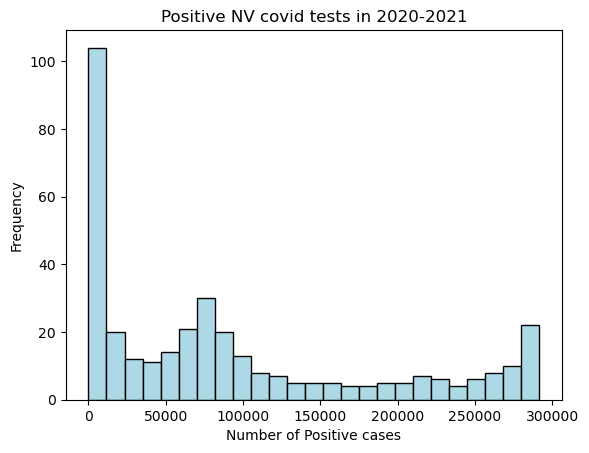

In [3]:
import matplotlib.pyplot as plt
import numpy as py

plt.hist(NV_covid_df['positive'], bins=25, color='lightblue', edgecolor='black')

# Add labels and title
plt.xlabel('Number of Positive cases')
plt.ylabel('Frequency')
plt.title('Positive NV covid tests in 2020-2021')

# Show the plot
plt.show()

### Adding a density plot

With an additional line of code we can add a density plot. The seaborn package is needed for the `sns` function applied below.

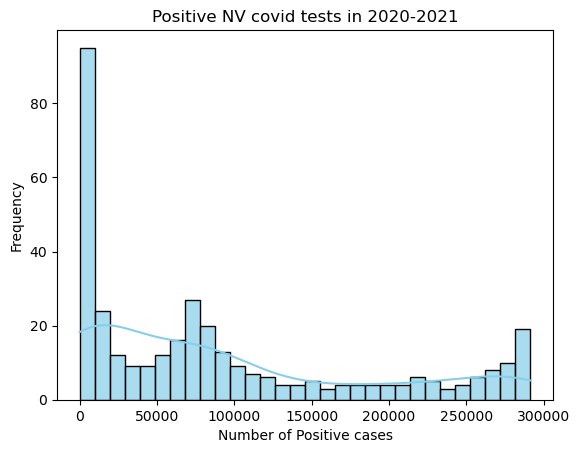

In [4]:
import seaborn as sns

#sns.set_style('whitegrid') turning this on 
sns.histplot(NV_covid_df['positive'], bins=30, kde=True, color='skyblue', edgecolor='black', alpha=0.7)
# Add labels and title
plt.xlabel('Number of Positive cases')
plt.ylabel('Frequency')
plt.title('Positive NV covid tests in 2020-2021')

# Show the plot
plt.show()# Creating a customized histogram with a density plot


## Scatter plots

Scatter plots are generally easiest with `plt.scatter`

Plot options include:

Size (`s`): The values are interpreted as areas, so the size grows quadratically.

Color (`c`): Can be a single color (e.g., 'blue'), a list of colors (e.g., ['red', 'blue']) or a colormap if you pass numeric values (e.g., using c=values and adding cmap='viridis').

Other Useful Options:

`alpha`: Controls transparency.
 
`edgecolors`: Adds borders around points.

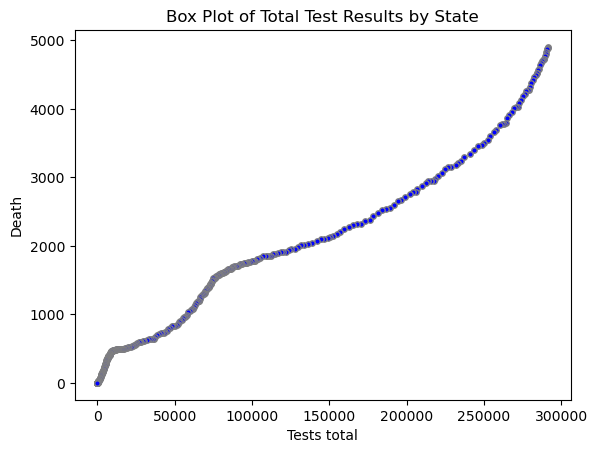

In [5]:
import matplotlib.pyplot as plt
import numpy as np


plt.scatter(y=NV_covid_df['death'], x=NV_covid_df['positive'], color='blue', edgecolor='gray', s=15)

# Label axes and plot
plt.title('Box Plot of Total Test Results by State')
plt.xlabel('Tests total')
plt.ylabel('Death')

plt.show()


## Using grouping variables to plot

Here lets read the covid data in, group data by state, and plot some of the variables across time.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

state_covid_sub_df = pd.read_csv('states_covid.csv',parse_dates=['date'],infer_datetime_format=True,index_col=None)
state_covid_sub_df.head()

/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_67975/2964205761.py:5: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  state_covid_sub_df = pd.read_csv('states_covid.csv',parse_dates=['date'],infer_datetime_format=True,index_col=None)


,date,state,death,deathConfirmed,deathIncrease,deathProbable,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,...,totalTestResults,totalTestResultsIncrease,totalTestsAntibody,totalTestsAntigen,totalTestsPeopleAntibody,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
0,2021-02-23,AK,290.0,NaN,0,NaN,1260.0,1260.0,38.0,9,...,1653425.0,4640,NaN,NaN,NaN,NaN,NaN,0,1653425.0,4640
1,2021-02-23,AL,9660.0,7575.0,68,2085.0,45250.0,45250.0,762.0,122,...,2265086.0,4825,NaN,NaN,115256.0,NaN,2265086.0,4825,NaN,0
2,2021-02-23,AR,5377.0,4321.0,14,1056.0,14617.0,14617.0,545.0,47,...,2609837.0,4779,NaN,NaN,NaN,436309.0,NaN,0,2609837.0,4779
3,2021-02-23,AS,0.0,NaN,0,NaN,NaN,NaN,NaN,0,...,2140.0,0,NaN,NaN,NaN,NaN,NaN,0,2140.0,0
4,2021-02-23,AZ,15650.0,13821.0,148,1829.0,57072.0,57072.0,1515.0,78,...,7478323.0,19439,435091.0,NaN,NaN,NaN,3709365.0,6212,7478323.0,19439


### Using grouping variables to plot

Below Ive illustrated some options for visualizing state level data for one variable at t a time. This might give you an idea of how versatile data visualization can be in python, how easy it can be, and how nice you can make figures look. First, lets group by state and make box plots. Code below uses `seaborn` to make a nice looking box plot.

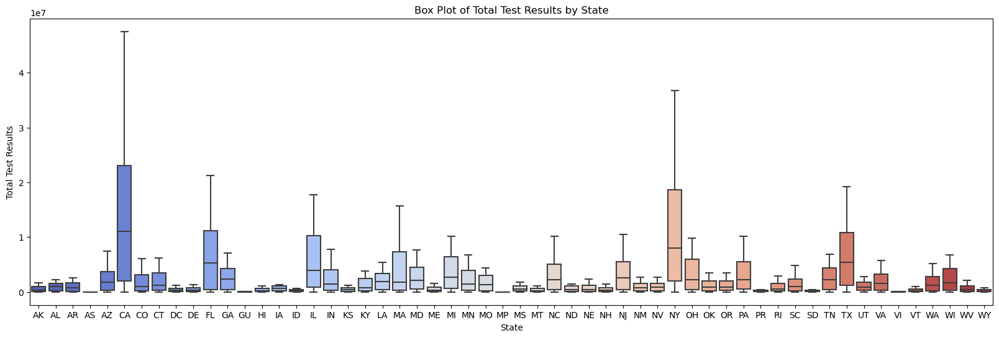

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 6))  # Set the size of the plot
#sns.boxplot(x='state', y='totalTestResults', color= 'lavender', data=state_covid_sub_df)
sns.boxplot(x='state', y='totalTestResults', data=state_covid_sub_df, palette='coolwarm', fliersize=5)

# Labels
plt.title('Box Plot of Total Test Results by State')
plt.xlabel('State')
plt.ylabel('Total Test Results')

# Display the plot
plt.show()

#### The below code sorts states by medians, adds strip plots, rotates the x axis, changes y to logarithmic, and highlights outliers.

#### An optional way to show this data might be with a strip plot which can also be done with `seaborn`:

/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_67975/3924560637.py:7: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(x='state', y='totalTestResults', data=state_covid_sub_df, palette='Set1', jitter=True, alpha=0.5, linewidth=.04)


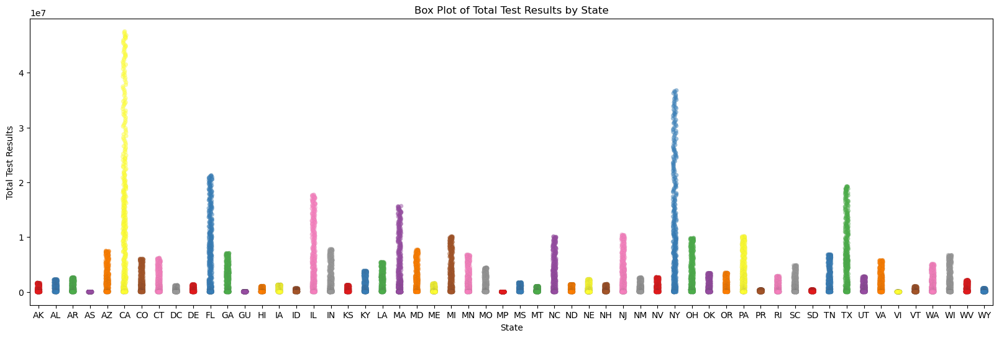

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create the box plot
plt.figure(figsize=(20, 6))  # Set the size of the plot
sns.stripplot(x='state', y='totalTestResults', data=state_covid_sub_df, palette='Set1', jitter=True, alpha=0.5, linewidth=.04)

# Customize the plot (optional)
plt.title('Box Plot of Total Test Results by State')
plt.xlabel('State')
plt.ylabel('Total Test Results')

# Display the plot
plt.show()

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 6))  # Set the size of the plot

# Sort states by median total test results
state_order = state_covid_sub_df.groupby('state')['totalTestResults'].median().sort_values().index

# Create the box plot with additional enhancements
sns.boxplot(x='state', y='totalTestResults', data=state_covid_sub_df, 
            order=state_order, palette='coolwarm')

# Add a strip plot for data points
sns.stripplot(x='state', y='totalTestResults', data=state_covid_sub_df, 
              color='black', jitter=True, alpha=0.5)

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add a logarithmic scale for y-axis (if applicable)
plt.yscale('log')
plt.ylabel('Total Test Results (Log Scale)')

# Add title and labels
plt.title('Box Plot of Total Test Results by State')
plt.xlabel('State')
plt.ylabel('Total Test Results')

# Show the plot
plt.show()


NameError: name 'state_covid_sub_df' is not defined

<Figure size 2000x600 with 0 Axes>

#### plots can be written to files using `plt.savefig`

Usage: `plt.savefig('filename.pdf', format='pdf')`

- You can specify a different path and filename if desired.
- The format='pdf' argument is one option, others include .png, .jpeg, .svg, etc.
- `dpi` is used to specify dots per inch, effects file size.

In [ ]:
plt.savefig('violin_plot_eg.pdf', bbox_inches='tight', dpi=300)

#### Line plots of totalTestResults by state

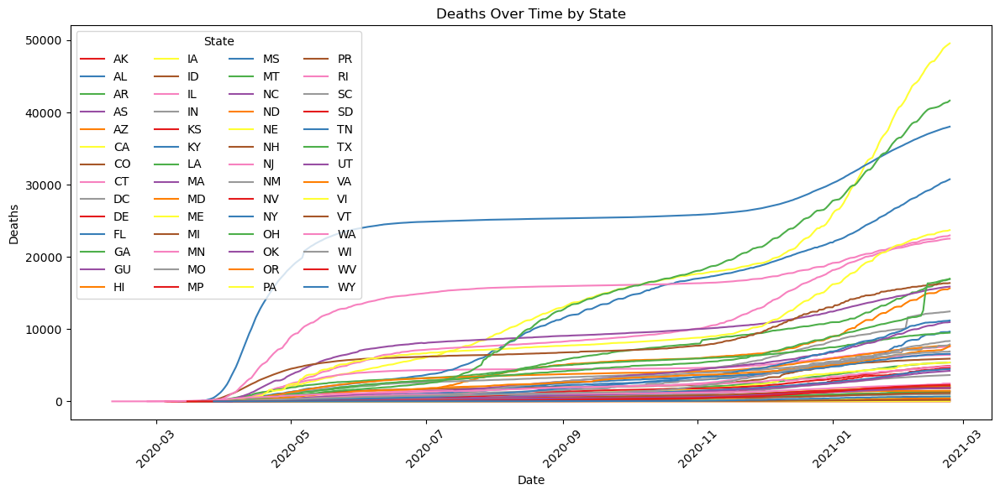

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Create the line plot
plt.figure(figsize=(12, 6))  # Set the size of the plot
#sns.lineplot(x='date', y='death', hue='state', palette='Set1', data=state_covid_sub_df, markers=True)
sns.lineplot(x='date', y='death', hue='state', palette='Set1', data=state_covid_sub_df, markers='o', markerfacecolor='red', markeredgewidth=2)

# Customize the plot
plt.title('Deaths Over Time by State')
plt.xlabel('Date')
plt.ylabel('Deaths')
plt.xticks(rotation=45)  # Rotate date labels for better readability
plt.legend(title='State', ncol=4, loc='upper left') 

# Display the plot
plt.tight_layout()
plt.show()

#### We could look at the same data with seaborn's `FacetGrid`, which will create separate plots for each state:

/Users/thomasparchman/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/m2/04t_0bnx1rv6940_lc07qdbm0000gn/T/ipykernel_67975/2633319726.py:12: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


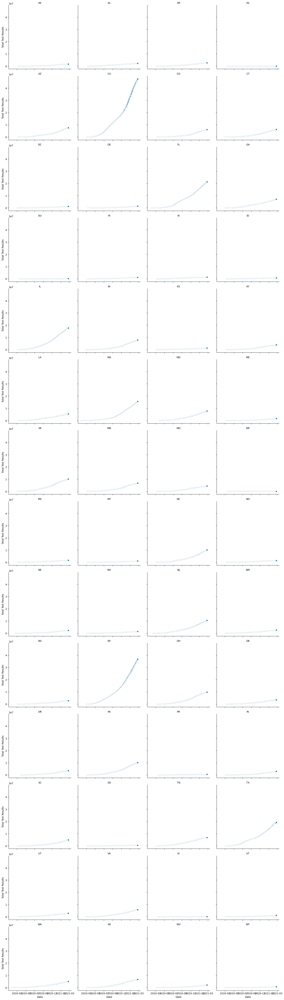

In [11]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


g = sns.FacetGrid(state_covid_sub_df, col="state", col_wrap=4, height=4)
g.map(sns.lineplot, "date", "totalTestResults", marker='o')

g.set_axis_labels("Date", "Total Test Results")
g.set_titles("{col_name}")

plt.tight_layout()
plt.show()


#### Choropleth maps provide a geographical representation of your data, with each state represented by a color intensity based on totalTestResults. This is especially useful for showing state-wise data geographically.

In [12]:
import plotly.express as px

fig = px.choropleth(state_covid_sub_df, locations="state", locationmode="USA-states",
                    color="totalTestResults", hover_name="state",
                    color_continuous_scale="Plasma", 
                    labels={"totalTestResults": "Total Test Results"})

fig.update_layout(title_text="Total Test Results by State (Choropleth)",
                  geo=dict(scope='usa'))
fig.show()


#### Bubble map using px

In [47]:
import plotly.express as px

fig = px.scatter_geo(state_covid_sub_df, locations="state", locationmode="USA-states",
                     size="totalTestResults", hover_name="state",
                     color="totalTestResults", color_continuous_scale="Plasma",
                     title="Bubble Map of Total Test Results by State")

fig.update_layout(geo=dict(scope='usa'))
fig.show()

ValueError: 
    Invalid element(s) received for the 'size' property of scattergeo.marker
        Invalid elements include: [nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]

    The 'size' property is a number and may be specified as:
      - An int or float in the interval [0, inf]
      - A tuple, list, or one-dimensional numpy array of the above

In [13]:
import plotly.express as px

fig = px.bar(state_covid_sub_df, x='totalTestResults', y='state', 
             orientation='h', color='totalTestResults', 
             color_continuous_scale='Viridis', 
             labels={'totalTestResults': 'Total Test Results', 'state': 'State'},
             title='Total Test Results by State')

fig.update_layout(yaxis={'categoryorder': 'total ascending'})
fig.show()

Remember that python has great built in date attributes. Plot deaths by day and find the days with the most deaths 

,death,negative,positive,totalTestResults
date,,,,
Tuesday,79269.0,26076775.0,4805720.0,50582871.0


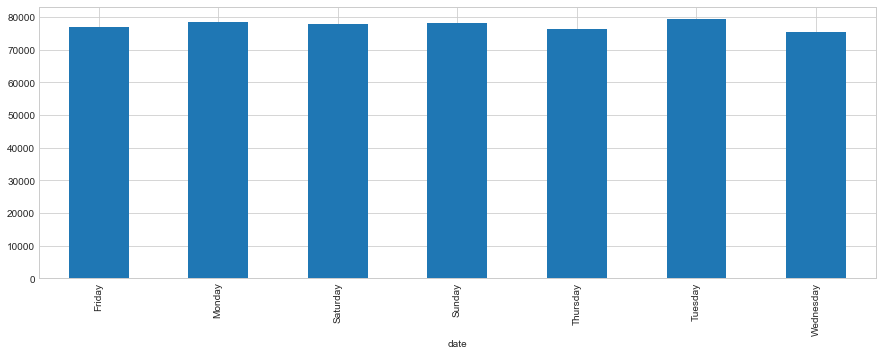

In [154]:
#### deaths by day of the week ####
weekday_counts = NV_covid_df.groupby(NV_covid_df['date'].dt.day_name()).aggregate(sum)
weekday_counts

weekday_counts.death.plot(kind='bar')

weekday_counts[weekday_counts.death == weekday_counts.death.max()]

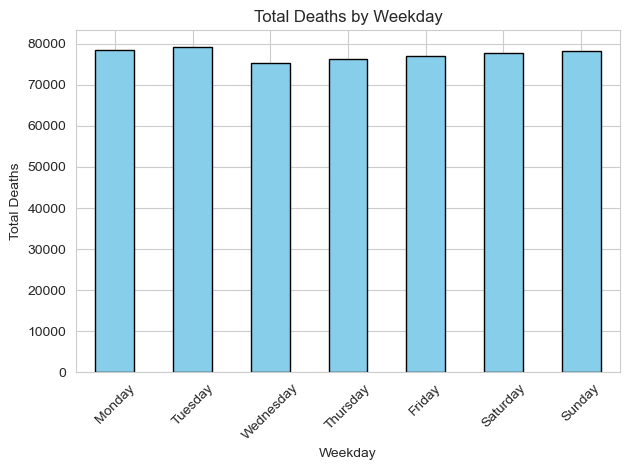

Day with maximum deaths:
           death
date            
Tuesday  79269.0


In [84]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure the 'date' column is in datetime format
NV_covid_df['date'] = pd.to_datetime(NV_covid_df['date'])

# Group by day of the week and sum the 'death' column
weekday_counts = NV_covid_df.groupby(NV_covid_df['date'].dt.day_name()).agg({'death': 'sum'})

# Reorder the weekdays
weekday_counts = weekday_counts.reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
)

# Plot the bar chart for death counts by weekday
weekday_counts.death.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Total Deaths by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Total Deaths')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Find the weekday with the highest number of deaths
max_death_day = weekday_counts[weekday_counts.death == weekday_counts.death.max()]
print("Day with maximum deaths:")
print(max_death_day)


Days with most deaths are **Tuesday**. Anyone know why? "most places are closed on the weekend, many counts are reports happen on monday" 

#### Maps

Here is a quick example of plotting points on a map using `plotly.express`. Note the map below is an interactive figure - you can zoom in and out, and if you hover the pointer over points, information on them will appear.

In [3]:
import pandas as pd
import plotly.express as px

muricata_df = pd.read_csv('muricata_pops_lat_long.csv')


 
# Create a scatter mapbox plot
fig = px.scatter_mapbox(muricata_df, lat='lat', lon='long', color='region',
                        hover_name='pop', color_continuous_scale='Viridis',
                        size_max=15, zoom=7)
 
fig.update_layout(mapbox_style="carto-positron", title="Geospatial Data Points")
fig.show()



# Appendix Common and Useful `matplotlib` (Pyplot/Axes) Functions

| **Category** | **Function / Method** | **Example Syntax** | **Purpose / Description** |
|--------------|------------------------|---------------------|----------------------------|
| **Setup & Styles** | `import matplotlib.pyplot as plt` | `import matplotlib.pyplot as plt` | Standard import for plotting |
|  | `plt.style.use()` | `plt.style.use("seaborn-v0_8-whitegrid")` | Apply a global style |
| **Figure & Axes** | `plt.figure()` | `plt.figure(figsize=(8,4), dpi=150)` | Create a new figure |
|  | `plt.subplots()` | `fig, ax = plt.subplots(1,2, figsize=(10,4), sharey=True)` | Create figure + grid of axes |
|  | `fig.add_subplot()` | `ax = fig.add_subplot(111)` | Add an Axes to an existing Figure |
| **Basic Plots** | `ax.plot()` | `ax.plot(x, y, lw=2, marker="o")` | Line plot |
|  | `ax.scatter()` | `ax.scatter(x, y, s=30, alpha=0.7)` | Scatter plot |
|  | `ax.bar()` / `ax.barh()` | `ax.bar(categories, values)` | Vertical / horizontal bar charts |
|  | `ax.hist()` | `ax.hist(data, bins=30, alpha=0.8)` | Histogram |
|  | `ax.boxplot()` | `ax.boxplot([a,b], labels=["A","B"])` | Box-and-whisker plot |
|  | `ax.violinplot()` | `ax.violinplot(data, showmeans=True)` | Violin plot |
|  | `ax.fill_between()` | `ax.fill_between(x, y1, y2)` | Shaded area between curves |
| **Images & Heatmaps** | `ax.imshow()` | `ax.imshow(M, aspect="auto", origin="lower")` | Display 2D array as image |
|  | `ax.pcolormesh()` | `pcm = ax.pcolormesh(X, Y, Z)` | Pseudocolor plot (irregular grids) |
|  | `fig.colorbar()` | `fig.colorbar(pcm, ax=ax)` | Add a colorbar |
| **Error & CI** | `ax.errorbar()` | `ax.errorbar(x, y, yerr=se, fmt="o")` | Plot with error bars |
|  | `ax.hlines()` / `ax.vlines()` | `ax.axhline(0, ls="--")` | Reference lines |
| **Axes Labels & Titles** | `ax.set_title()` | `ax.set_title("My Plot")` | Title |
|  | `ax.set_xlabel()` / `ax.set_ylabel()` | `ax.set_xlabel("Time (s)")` | Axis labels |
| **Ticks & Limits** | `ax.set_xlim()` / `ax.set_ylim()` | `ax.set_xlim(0, 100)` | Axis limits |
|  | `ax.set_xticks()` / `ax.set_xticklabels()` | `ax.set_xticks([0,50,100])` | Tick placement/labels |
|  | `ax.tick_params()` | `ax.tick_params(axis="x", rotation=45)` | Tick appearance |
| **Legends & Annotation** | `ax.legend()` | `ax.legend(title="Groups", loc="best")` | Legend |
|  | `ax.annotate()` | `ax.annotate("peak", xy=(x0,y0), xytext=(...))` | Text with arrow |
|  | `ax.text()` | `ax.text(0.05, 0.95, "Note", transform=ax.transAxes)` | Fixed-position note |
| **Layout** | `plt.tight_layout()` | `plt.tight_layout()` | Prevent label overlap |
|  | `fig.subplots_adjust()` | `fig.subplots_adjust(wspace=0.3, hspace=0.4)` | Manual spacing |
|  | `fig.suptitle()` | `fig.suptitle("Multi-panel figure")` | Title for entire figure |
| **Multiplot & Grids** | `plt.subplots(nrows, ncols)` | `fig, axes = plt.subplots(2,3)` | Grid of subplots |
|  | `GridSpec` | `gs = fig.add_gridspec(2,3); ax = fig.add_subplot(gs[1, :])` | Flexible subplot layout |
| **Multiple Axes** | `ax.twinx()` / `ax.twiny()` | `ax2 = ax.twinx(); ax2.plot(x, y2)` | Secondary x/y axes |
| **Dates & Time Series** | `matplotlib.dates` | `ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))` | Custom date formatting |
| **Saving** | `plt.savefig()` | `plt.savefig("fig.png", dpi=300, bbox_inches="tight")` | Save static figure |
|  | `fig.savefig()` | `fig.savefig("fig.pdf")` | Save via Figure object |
| **Interactivity (basic)** | `%matplotlib inline/qt` | In notebooks: `%matplotlib inline` | Backend for inline or interactive |
| **3D (optional)** | `projection="3d"` | `ax = fig.add_subplot(111, projection="3d")` | 3D axes (mplot3d) |

---

# Appendix B: Common and Useful `seaborn` Functions

| **Category** | **Function / Method** | **Example Syntax** | **Purpose / Description** |
|--------------|------------------------|---------------------|----------------------------|
| **Setup & Theme** | `import seaborn as sns` | `import seaborn as sns` | Standard import |
|  | `sns.set_theme()` | `sns.set_theme(style="whitegrid", context="talk")` | Global theme, context, and palette |
|  | `sns.set_style()` / `sns.set_context()` | `sns.set_style("ticks"); sns.set_context("paper")` | Style + scale elements |
|  | `sns.color_palette()` | `sns.color_palette("viridis", as_cmap=True)` | Palettes / colormaps |
| **Relational** | `sns.scatterplot()` | `sns.scatterplot(data=df, x="PC1", y="PC2", hue="species")` | Scatter with grouping |
|  | `sns.lineplot()` | `sns.lineplot(data=df, x="time", y="temp", hue="logger")` | Lines with CI |
|  | `sns.relplot()` | `sns.relplot(data=df, x="x", y="y", kind="scatter", col="site")` | Faceted relational plots |
| **Distribution** | `sns.histplot()` | `sns.histplot(data=df, x="value", bins=30, kde=True)` | Histogram (+ KDE) |
|  | `sns.kdeplot()` | `sns.kdeplot(data=df, x="value", fill=True)` | Kernel density estimate |
|  | `sns.ecdfplot()` | `sns.ecdfplot(data=df, x="value", hue="group")` | Empirical CDFs |
|  | `sns.displot()` | `sns.displot(df, x="value", col="group", kde=True)` | Faceted distributions |
| **Categorical** | `sns.barplot()` | `sns.barplot(data=df, x="treatment", y="response", ci=95)` | Mean + CI bars |
|  | `sns.pointplot()` | `sns.pointplot(data=df, x="dose", y="y", hue="group")` | Means with CI lines/points |
|  | `sns.countplot()` | `sns.countplot(data=df, x="species")` | Category counts |
|  | `sns.boxplot()` | `sns.boxplot(data=df, x="group", y="value")` | Box-and-whisker by group |
|  | `sns.violinplot()` | `sns.violinplot(data=df, x="group", y="value", cut=0)` | Violin plots |
|  | `sns.stripplot()` / `sns.swarmplot()` | `sns.stripplot(data=df, x="group", y="value", jitter=0.2)` | Raw data over categories |
|  | `sns.catplot()` | `sns.catplot(df, x="g", y="v", kind="box", col="site")` | Faceted categorical plots |
| **Matrix / Heatmaps** | `sns.heatmap()` | `sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)` | Heatmap (e.g., correlations) |
|  | `sns.clustermap()` | `sns.clustermap(df_piv, metric="euclidean", method="ward")` | Hierarchical clustering heatmap |
| **Regression** | `sns.regplot()` | `sns.regplot(x="x", y="y", data=df, ci=95, scatter_kws={"s":20})` | Scatter with linear fit |
|  | `sns.lmplot()` | `sns.lmplot(data=df, x="x", y="y", hue="group", col="site")` | Faceted regression |
| **Grids** | `sns.FacetGrid()` | `g = sns.FacetGrid(df, col="site", row="year"); g.map(sns.histplot, "value")` | Custom faceting |
|  | `sns.PairGrid()` | `g = sns.PairGrid(df, vars=["x","y","z"]); g.map_diag(sns.kdeplot); g.map_offdiag(sns.scatterplot)` | Customizable pairwise grid |
|  | `sns.pairplot()` | `sns.pairplot(df, hue="species", diag_kind="kde")` | Quick pairwise matrix |
|  | `sns.JointGrid()` / `sns.jointplot()` | `sns.jointplot(data=df, x="x", y="y", kind="kde")` | Bivariate + marginals |
| **Aesthetics & Post-hoc** | `ax = sns.*(...); ax.set(...)` | `ax = sns.boxplot(...); ax.set(xlabel="A", ylabel="B", title="T")` | Use Matplotlib Axes methods to fine-tune |
|  | `sns.move_legend()` | `sns.move_legend(ax, "upper left", bbox_to_anchor=(1,1))` | Reposition legend |
|  | `sns.despine()` | `sns.despine(offset=5, trim=True)` | Remove top/right spines |
| **Statistical CI Control** | `ci` / `errorbar` | `sns.lineplot(..., errorbar=("ci", 95))` | Control confidence intervals |
| **Saving Figures** | `plt.savefig()` | `plt.savefig("seaborn_plot.png", dpi=300, bbox_inches="tight")` | Save Seaborn plots (Matplotlib backend) |

---

